# SQL로 조회 함수 만들기

**이 노트북에서 할 일**

1. 02절의 고객 표와 주문 표를 SQLite 데이터베이스 파일에 테이블로 만들고 행을 넣습니다.
2. SQL 문장으로 행을 고르고 정렬하고 두 테이블을 이은 뒤, 고객 번호로 주문을 찾는 함수를 만듭니다.
3. 입력 글을 SQL에 이어 붙인 함수가 다른 고객의 주문까지 꺼내는 장면을 보고, 자리표시자로 고칩니다.

**준비물** — API 키 불필요. 데이터베이스 파일은 노트북이 임시 폴더에 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**강의와 실습 범위** — 강의 시간에는 4~10번과 14·15·17·18번 소제목을 설명합니다.
4~10번은 테이블 만들기부터 JOIN까지이고, 14·15·17·18번은 조회 함수와 Before/After입니다.
2·3번, 11~13번(제약과 남은 행 수), 16번(값 바꿔 보기)은 셀을 함께 실행합니다. 결과 읽기는 실습 시간에 이어서 읽습니다.

**기준 버전** — 이 절은 따로 설치하는 패키지 없이 Python에 들어 있는 모듈 sqlite3만 씁니다.
교재 출력은 2026-09-16에 Python 3.12.13과 그 Python이 쓰는 SQLite 3.53.1로 만들었습니다.
Python 3.12 설명서에 따르면 모듈 sqlite3는 SQLite 3.7.15 이상을 요구합니다.
외래 키 검사는 SQLite 3.6.19부터 있습니다. 다른 SQLite 버전에서는 오류 메시지 글이 다를 수 있고, 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch04-data-tools`에서 Ch 1 3절처럼 `uv sync --locked`로 환경을 만듭니다.
커널에서 이 폴더의 `.venv`를 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

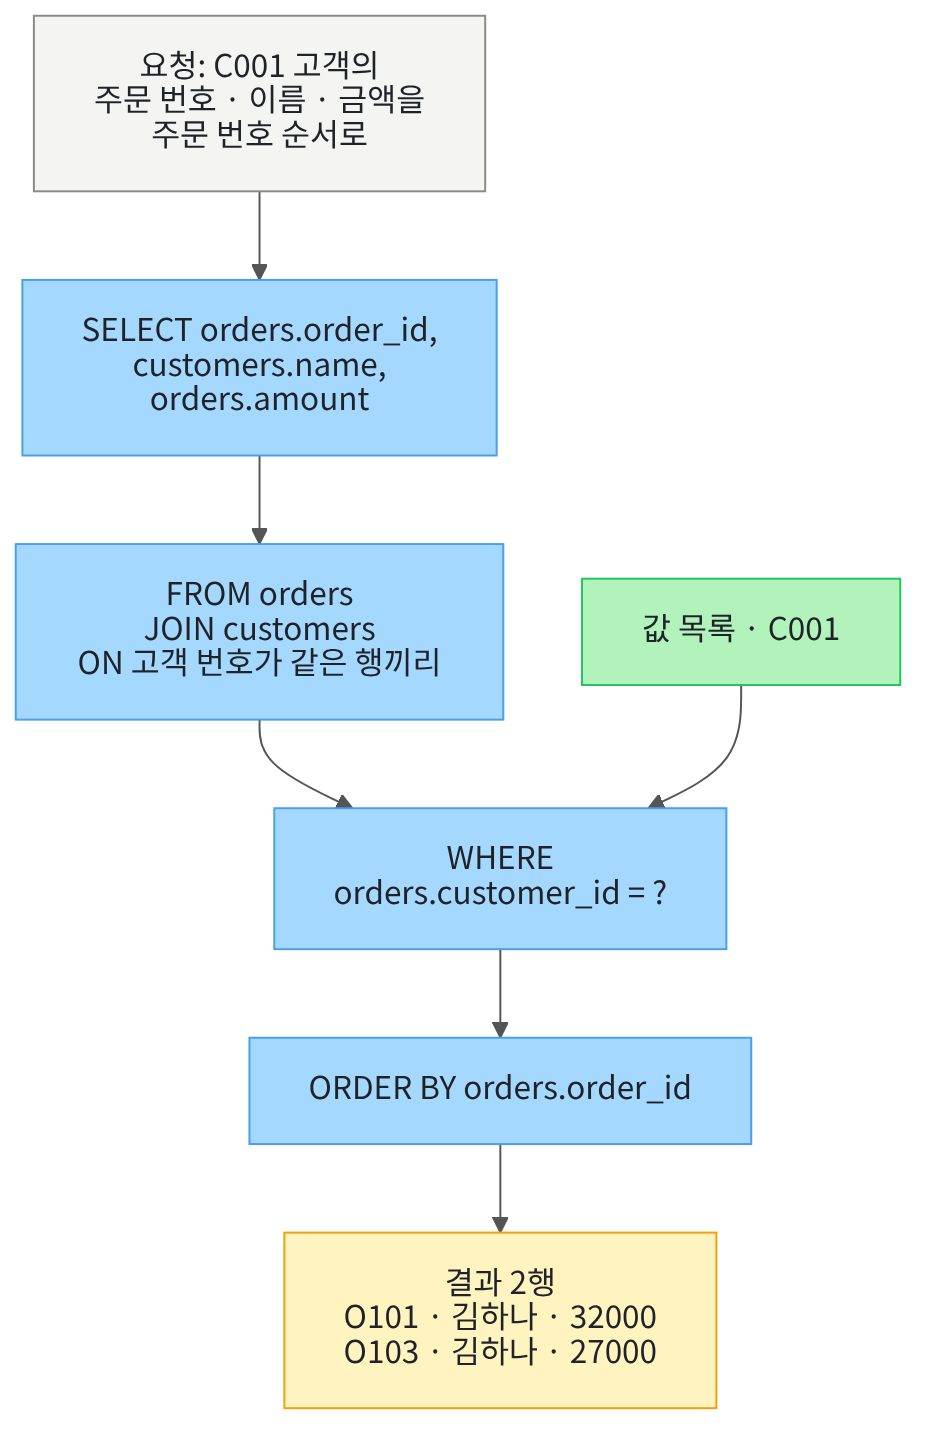

위에서 아래로 읽습니다. 맨 위 회색 상자는 말로 한 요청이고, 그 아래 파란 상자 네 개가 요청을 나눠 적은 SQL 조각입니다.
오른쪽 초록 상자 C001은 함수가 받은 고객 번호로, WHERE 조각의 물음표 자리에 들어갑니다.
맨 아래 노란 상자는 노트북에서 출력으로 확인한 두 행입니다.

## 1. 준비

이 노트북은 데이터베이스 파일 하나를 만듭니다. 01·02절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
실습 폴더에는 파일이 생기지 않습니다.

코드의 import 두 줄은 Ch 2 07절에서 배운 import 문입니다. 표준 라이브러리 모듈 os와 tempfile을 불러옵니다.

In [1]:
# 데이터베이스 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch04-03-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 데이터베이스와 sqlite3

데이터베이스(database)는 여러 표를 한곳에 모아 두고, 정해진 문장으로 읽고 쓰는 저장소입니다.
도서관 서고와 비슷합니다. 책장이 표이고, 사서에게 요청서를 내면 사서가 책을 찾아 줍니다.

이 절에서 쓰는 SQLite 데이터베이스는 표 여러 개를 파일 하나에 담습니다. 서버 프로그램을 따로 켜지 않아도 됩니다.
표준 라이브러리에 SQLite를 다루는 모듈 sqlite3가 들어 있어서, 따로 설치하지 않습니다.

실행 전에 예상합니다. 숫자와 점으로 된 버전 글 한 줄이 출력될 것입니다.

In [2]:
# Python에 들어 있는 SQLite 모듈을 불러옵니다
import sqlite3

# sqlite_version에는 이 모듈이 함께 쓰는 SQLite의 버전 글이 들어 있습니다
print("SQLite 버전:", sqlite3.sqlite_version)

SQLite 버전: 3.53.1


**결과 읽기** — 출력은 `SQLite 버전: 3.53.1`입니다. 이 커널의 Python 3.12.13이 쓰는 SQLite 버전입니다.
다른 버전이 나오면 뒤에서 보는 오류 메시지 글이 조금 다를 수 있습니다.

## 3. 데이터베이스 파일 열기

데이터베이스와 명령을 주고받으려면 먼저 연결(connection)을 만듭니다. 전화를 걸어 통화가 이어진 상태와 비슷합니다.
함수 `sqlite3.connect()`에 파일 이름을 넣으면 연결 객체를 반환합니다. 그 이름의 파일이 없으면 새로 만듭니다.

데이터베이스에 표를 만들고, 행을 넣고, 읽으라고 적는 언어가 SQL(Structured Query Language)입니다.
연결 객체의 메서드 `execute()`는 SQL 문장 글 하나를 데이터베이스에 보내 실행합니다.

첫 SQL 문장 `PRAGMA foreign_keys = ON`은 SQLite의 설정 하나인 외래 키 검사를 켭니다.
SQLite 데이터베이스는 이 검사를 끈 채로 시작하고, 연결마다 따로 켜야 합니다. 검사가 하는 일은 12절에서 확인합니다.

실행 전에 예상합니다. 폴더 목록에 `shop.db` 하나가 보일 것입니다.

In [3]:
# shop.db 파일에 연결하고, 이 연결에서 외래 키 검사를 켭니다
# connect()는 파일이 없으면 새로 만들고, 연결 객체를 반환합니다
connection = sqlite3.connect("shop.db")
connection.execute("PRAGMA foreign_keys = ON")
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['shop.db']


**결과 읽기** — 현재 작업 폴더의 파일은 `['shop.db']`로 예상과 같습니다.
설정을 켜는 문장은 출력을 남기지 않습니다. 아직 표가 없어서 이 파일은 비어 있습니다.

## 4. 고객 표 만들기 — CREATE TABLE

데이터베이스 안의 표를 테이블(table)이라고 부릅니다. 02절에서 CSV 파일로 만든 표와 같은 모양입니다.
SQL 문장 `CREATE TABLE`은 새 테이블을 만듭니다. 새 장부의 첫 줄에 칸 이름을 적어 두는 일과 비슷합니다.

괄호 안에는 열마다 이름, 자료형, 조건을 한 줄씩 적고 쉼표로 나눕니다.
자료형 `TEXT`는 글자입니다. 조건 `PRIMARY KEY`는 이 열을 02절의 기본 키로 정합니다.
조건 `NOT NULL`은 이 칸을 비워 둘 수 없다는 뜻입니다. 이렇게 테이블에 적어 둔 조건을 제약(constraint)이라고 부릅니다.

SQL 문장이 여러 줄이라, Ch 2 05절의 여러 줄 글 `"""…"""`에 담아 변수에 저장한 뒤 넘깁니다.
메서드 `execute()`가 반환하는 값은 7절에서 씁니다. 여기서는 변수 `cursor`에 받아만 둡니다.
실행 전에 예상합니다. 테이블을 만드는 문장은 출력을 남기지 않을 것입니다.

In [4]:
# 고객 번호를 기본 키로 둔 고객 테이블을 만듭니다
customer_table_sql = """CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    name TEXT NOT NULL
)"""
cursor = connection.execute(customer_table_sql)

**결과 읽기** — 출력이 없습니다. 오류 없이 끝났으므로 고객 테이블 `customers`가 만들어졌습니다.
테이블이 정말 있는지는 6절에서 행을 넣으며 확인합니다.

## 5. 주문 표 만들기 — FOREIGN KEY

주문 테이블의 열은 02절 `orders.csv`와 같은 네 개입니다. 금액 열의 자료형 `INTEGER`는 정수입니다.

마지막 줄 `FOREIGN KEY (customer_id) REFERENCES customers (customer_id)`가 02절의 외래 키를 적은 제약입니다.
뜻은 「이 테이블의 고객 번호 열에는, 고객 테이블의 고객 번호 열에 있는 값만 넣을 수 있다」입니다.
주문 쪽지에 붙일 스티커 색을, 카드 상자에 이미 있는 카드 색에서만 고르는 일과 같습니다.

실행 전에 예상합니다. 이 셀도 출력이 없을 것입니다.

In [5]:
# 고객 번호를 외래 키로 둔 주문 테이블을 만듭니다
order_table_sql = """CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    status TEXT NOT NULL,
    amount INTEGER NOT NULL,
    FOREIGN KEY (customer_id) REFERENCES customers (customer_id)
)"""
cursor = connection.execute(order_table_sql)

**결과 읽기** — 출력이 없습니다. 이제 `shop.db` 안에 테이블 두 개가 있습니다.
두 테이블의 고객 번호 열은 기본 키와 외래 키로 이어졌습니다.

## 6. 두 표에 행 넣기 — INSERT INTO

SQL 문장 `INSERT INTO 테이블 VALUES (값, 값)`은 테이블에 행을 넣습니다. 장부에 새 줄을 적는 일입니다.
괄호 하나가 행 하나이고, 괄호 여러 개를 쉼표로 이으면 여러 행을 한 번에 넣습니다.
SQL에서 글자 값은 작은따옴표로 감싸고, 숫자는 그대로 적습니다.

메서드 `execute()`가 반환하는 커서(cursor) 객체의 속성 `rowcount`에는 바뀐 행 수가 들어 있습니다.
고객을 먼저 넣습니다. 외래 키 검사가 켜져 있어서, 주문이 가리킬 고객이 먼저 있어야 합니다.

넣은 행은 연결의 메서드 `commit()`을 불러야 파일에 확정됩니다. 이 확정을 커밋(commit)이라고 부릅니다.
Ch 3 01절의 Git 커밋과 이름은 같지만, 여기서는 데이터베이스에 한 변경을 확정하는 일입니다.

실행 전에 예상합니다. 고객 테이블에 2행, 주문 테이블에 3행을 넣었다고 출력될 것입니다.

In [6]:
# 고객 두 명과 주문 세 건을 두 테이블에 넣습니다
cursor = connection.execute("""INSERT INTO customers VALUES
    ('C001', '김하나'),
    ('C002', '이두리')""")
print("고객 테이블에 넣은 행 수:", cursor.rowcount)
cursor = connection.execute("""INSERT INTO orders VALUES
    ('O101', 'C001', 'paid', 32000),
    ('O102', 'C002', 'pending', 18000),
    ('O103', 'C001', 'paid', 27000)""")
print("주문 테이블에 넣은 행 수:", cursor.rowcount)
# 넣은 행을 파일에 확정합니다
connection.commit()

고객 테이블에 넣은 행 수: 2
주문 테이블에 넣은 행 수: 3


**결과 읽기** — 출력은 `고객 테이블에 넣은 행 수: 2`와 `주문 테이블에 넣은 행 수: 3`으로 예상과 같습니다.
커밋은 출력을 남기지 않습니다. 넣은 행은 15절에서 새 연결을 열어 읽어 봅니다.

## 7. 표 전체 읽기 — SELECT와 FROM

SQL 문장 `SELECT 열 FROM 테이블`은 테이블에서 행을 읽습니다. 사서에게 「주문 장부의 모든 칸을 보여 주세요」라고 적어 내는 요청입니다.
명령 `SELECT` 뒤에는 읽을 열을, `FROM` 뒤에는 테이블 이름을 적습니다. 별표 `*`는 모든 열이라는 뜻입니다.

읽기 문장을 실행하면 커서가 결과 행을 들고 있습니다. 커서의 메서드 `fetchall()`은 남은 결과 행을 모두 목록으로 반환합니다.
목록 안의 행 하나는 Ch 2 03절에서 배운 튜플이고, 열 순서대로 값이 들어 있습니다.

실행 전에 예상합니다. 주문 세 행이 튜플 세 개로 출력될 것입니다.

In [7]:
# 주문 테이블의 모든 열과 모든 행을 읽습니다
cursor = connection.execute("SELECT * FROM orders")
# fetchall()은 결과 행을 튜플 목록으로 반환합니다
rows = cursor.fetchall()
print("읽은 행:")
for row in rows:
    print(row)

읽은 행:
('O101', 'C001', 'paid', 32000)
('O102', 'C002', 'pending', 18000)
('O103', 'C001', 'paid', 27000)


**결과 읽기** — 라벨 줄 아래 첫 줄 `('O101', 'C001', 'paid', 32000)`부터 세 줄이 출력되었습니다.
튜플 안의 값은 테이블을 만들 때 적은 열 순서입니다. 금액 `32000`은 따옴표가 없어 정수입니다.

이번 출력은 넣은 순서와 같습니다. 하지만 SQLite 설명서는 순서를 정하지 않은 읽기의 행 순서를 약속하지 않습니다.
순서를 정하는 방법은 9절에서 봅니다.

## 8. 조건으로 행 고르기 — WHERE

명령 `WHERE` 뒤에는 남길 행의 조건을 적습니다. 「고객 번호가 C001인 주문만」처럼 장부에서 줄을 고르는 일입니다.
01절에서 마스크를 `loc`에 넣어 행을 고르던 일을 SQL 문장 안에 적는 모양입니다.

같은지 비교할 때 SQL에서는 `=` 하나를 씁니다. 뜻은 Python의 `==`와 같습니다.
이번에는 `SELECT` 뒤에 열 이름 두 개를 적어, 주문 번호와 금액만 읽습니다.

실행 전에 예상합니다. 김하나 고객의 주문 O101과 O103이 값 두 개짜리 튜플로 나올 것입니다.

In [8]:
# 고객 번호가 C001인 주문의 번호와 금액만 읽습니다
where_sql = "SELECT order_id, amount FROM orders WHERE customer_id = 'C001'"
cursor = connection.execute(where_sql)
rows = cursor.fetchall()
print("읽은 행:")
for row in rows:
    print(row)

읽은 행:
('O101', 32000)
('O103', 27000)


**결과 읽기** — 출력은 `('O101', 32000)`과 `('O103', 27000)` 두 줄로 예상과 같습니다.
고객 C002의 주문 O102는 조건에 맞지 않아 빠졌습니다.

## 9. 순서 정하기 — ORDER BY

명령 `ORDER BY` 뒤에는 정렬 기준 열을 적습니다. 주문 쪽지를 금액이 작은 것부터 늘어놓는 일입니다.
방향을 적지 않으면 작은 값부터 정렬합니다. 큰 값부터 정렬하려면 열 이름 뒤에 `DESC`를 붙이는데, 이번에는 실행하지 않았습니다.

앞 셀과 같은 조건에 `ORDER BY amount`만 더합니다. 문장이 길어져 여러 줄 글에 담았습니다.
실행 전에 예상합니다. 금액이 작은 O103이 O101보다 먼저 나올 것입니다.

In [9]:
# 같은 조건의 주문을 금액이 작은 것부터 정렬해 읽습니다
order_by_sql = """SELECT order_id, amount FROM orders
WHERE customer_id = 'C001'
ORDER BY amount"""
cursor = connection.execute(order_by_sql)
rows = cursor.fetchall()
print("읽은 행:")
for row in rows:
    print(row)

읽은 행:
('O103', 27000)
('O101', 32000)


**결과 읽기** — 라벨 줄 아래 첫 행이 `('O103', 27000)`, 둘째 행이 `('O101', 32000)`으로 순서가 바뀌었습니다.
고른 행은 앞 셀과 같은 두 개이고, 순서만 금액 기준으로 정해졌습니다.

## 10. 두 표 잇기 — JOIN과 ON

주문 테이블에는 고객 이름이 없습니다. 02절처럼 고객 번호로 고객 테이블을 이어야 이름을 읽을 수 있습니다.
명령 `JOIN` 뒤에는 이을 테이블을, `ON` 뒤에는 짝을 찾는 조건을 적습니다. 02절 `merge()`의 기본값과 같은 내부 조인입니다.

두 테이블에 모두 `customer_id` 열이 있어서, 열 이름 앞에 테이블 이름과 점을 붙여 구분합니다.
예를 들어 `orders.customer_id`는 주문 테이블의 고객 번호이고, `customers.customer_id`는 고객 테이블의 고객 번호입니다.

실행 전에 예상합니다. 02절 연결 결과처럼 3행이고, O101과 O103에 김하나가 붙을 것입니다.

In [10]:
# 주문 테이블과 고객 테이블을 고객 번호로 이어, 주문마다 고객 이름을 붙입니다
join_sql = """SELECT orders.order_id, customers.name, orders.amount
FROM orders
JOIN customers ON orders.customer_id = customers.customer_id
ORDER BY orders.order_id"""
cursor = connection.execute(join_sql)
rows = cursor.fetchall()
print("읽은 행:")
for row in rows:
    print(row)
print("연결한 행 수:", len(rows))

읽은 행:
('O101', '김하나', 32000)
('O102', '이두리', 18000)
('O103', '김하나', 27000)
연결한 행 수: 3


**결과 읽기** — `('O101', '김하나', 32000)`, `('O102', '이두리', 18000)`, `('O103', '김하나', 27000)` 세 줄입니다.
마지막 줄 `연결한 행 수: 3`도 02절에서 연결한 표의 행 수와 같습니다.

## 11. 제약이 막는 행 넣어 보기 — 겹친 기본 키

02절 Before에서는 C001 줄이 두 번 든 고객 표를 연결해 주문이 두 번 세어졌습니다.
데이터베이스는 그런 줄이 들어오는 순간에 막을 수 있습니다. 이미 있는 고객 번호 C001로 고객 한 명을 더 넣어 봅니다.

제약을 어기는 변경이 들어오면 모듈 sqlite3는 오류 IntegrityError를 냅니다.
이 오류 이름은 sqlite3 모듈 안에 있어 `sqlite3.IntegrityError`처럼 점으로 이어 적습니다. 02절 `pd.errors.MergeError`와 같은 모양입니다.
Ch 2 05절처럼 이 오류 이름만 받는 `try/except`로 감싸 셀을 끝까지 실행합니다.

실행 전에 예상합니다. 기본 키가 겹쳐서 넣기 오류 메시지가 출력될 것입니다.

In [11]:
# 이미 있는 고객 번호 C001로 고객 한 명을 더 넣어 봅니다
try:
    connection.execute("INSERT INTO customers VALUES ('C001', '김하나')")
except sqlite3.IntegrityError as error:
    print("넣기 오류:", error)

넣기 오류: UNIQUE constraint failed: customers.customer_id


**결과 읽기** — 출력은 `넣기 오류: UNIQUE constraint failed: customers.customer_id`입니다.
고객 테이블의 고객 번호 열이 「값이 모두 달라야 한다(UNIQUE)」는 조건을 어겼다는 뜻입니다.
기본 키에는 이 조건이 들어 있습니다. 행이 정말 들어가지 않았는지는 13절에서 셉니다.

## 12. 제약이 막는 행 넣어 보기 — 짝 없는 외래 키

02절 값 바꿔 보기에서는 고객 표에 없는 번호 C003을 쓴 주문이, 내부 조인에서 오류 없이 빠졌습니다.
이번에는 그런 주문을 넣는 순간에 막히는지 봅니다. 주문 O104의 고객 번호를 C003으로 적어 넣습니다.

실행 전에 예상합니다. 3절에서 켠 외래 키 검사가 이 행을 거절해, 넣기 오류 메시지가 출력될 것입니다.

In [12]:
# 고객 테이블에 없는 번호 C003으로 주문 한 건을 넣어 봅니다
try:
    connection.execute("INSERT INTO orders VALUES ('O104', 'C003', 'paid', 9000)")
except sqlite3.IntegrityError as error:
    print("넣기 오류:", error)

넣기 오류: FOREIGN KEY constraint failed


**결과 읽기** — 출력은 `넣기 오류: FOREIGN KEY constraint failed`입니다. 외래 키 제약을 어겼다는 뜻입니다.
고객 테이블에 C003이 없어서, 이 주문은 가리킬 고객이 없습니다.

## 13. 남은 행 세고 연결 닫기

두 오류 뒤에 테이블마다 행이 몇 개인지 셉니다. 넣으려던 C001 고객과 O104 주문이 들어가지 않았다면 6절과 같아야 합니다.
확인이 끝나면 연결의 메서드 `close()`로 연결을 닫습니다. 14절의 함수는 부를 때마다 새 연결을 엽니다.

실행 전에 예상합니다. 고객 테이블은 2행, 주문 테이블은 3행일 것입니다.

In [13]:
# 두 테이블에 남은 행 수를 셉니다
cursor = connection.execute("SELECT * FROM customers")
customer_rows = cursor.fetchall()
print("고객 테이블의 행 수:", len(customer_rows))
cursor = connection.execute("SELECT * FROM orders")
order_rows = cursor.fetchall()
print("주문 테이블의 행 수:", len(order_rows))
# 테이블을 만들고 확인하는 일이 끝나서 연결을 닫습니다
connection.close()

고객 테이블의 행 수: 2
주문 테이블의 행 수: 3


**결과 읽기** — 출력은 `고객 테이블의 행 수: 2`와 `주문 테이블의 행 수: 3`으로 6절과 같습니다.
제약에 걸린 두 행은 테이블에 들어가지 않았습니다. 연결을 닫는 줄은 출력을 남기지 않습니다.

## 14. 고객 번호로 주문을 찾는 함수 — 자리표시자

이제 8~10절의 조각을 모아, 고객 번호 하나를 받아 주문을 찾는 함수를 만듭니다.
고객 번호는 부를 때마다 달라집니다. 그래서 SQL 문장에는 값 대신 물음표 `?`를 적어 둡니다. 이 물음표를 자리표시자(placeholder)라고 부릅니다.

인쇄된 신청서의 빈칸과 비슷합니다. 누가 빈칸에 무엇을 적어도 인쇄된 문장은 바뀌지 않습니다.
메서드 `execute()`의 둘째 인자에 값 목록 `[customer_id]`를 넣으면, 목록의 값이 물음표 자리에 차례로 들어갑니다.

함수는 01절 `fetch_orders()`처럼 딕셔너리 목록을 반환합니다. 결과 튜플 한 줄은 Ch 2 03절의 풀어 담기로 변수 세 개에 나눕니다.
실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [14]:
# 데이터베이스 파일 이름과 고객 번호를 받아, 그 고객의 주문을 딕셔너리 목록으로 반환합니다
def find_customer_orders(database_name: str, customer_id: str) -> list:
    sql = """SELECT orders.order_id, customers.name, orders.amount
    FROM orders JOIN customers ON orders.customer_id = customers.customer_id
    WHERE orders.customer_id = ?
    ORDER BY orders.order_id"""
    connection = sqlite3.connect(database_name)
    # 둘째 인자 목록의 값이 물음표 자리에 들어갑니다
    cursor = connection.execute(sql, [customer_id])
    rows = cursor.fetchall()
    connection.close()
    records = []
    for order_id, name, amount in rows:
        record = {"order_id": order_id, "name": name, "amount": amount}
        records.append(record)
    return records

**결과 읽기** — 출력이 없습니다. 함수 `find_customer_orders()`가 정의되었습니다.
함수 안의 변수 `connection`은 Ch 2 04절의 지역 변수라, 13절에서 닫은 연결과 다른 새 연결입니다.

## 15. 함수 부르기 — 김하나 고객의 주문 합계

고객 번호 `"C001"`로 함수를 부르고, 반환된 딕셔너리의 금액을 Ch 2 03절의 `+=`로 더합니다.
실행 전에 예상합니다. 주문 O101과 O103이 나오고, 합계는 02절과 같은 59000일 것입니다.

In [15]:
# 고객 C001의 주문을 찾고, 금액을 모두 더합니다
kim_records = find_customer_orders("shop.db", "C001")
print("조회 결과:", kim_records)
kim_total = 0
for record in kim_records:
    kim_total += record["amount"]
print("김하나 고객의 주문 합계:", kim_total)
assert kim_total == 59000

조회 결과: [{'order_id': 'O101', 'name': '김하나', 'amount': 32000}, {'order_id': 'O103', 'name': '김하나', 'amount': 27000}]
김하나 고객의 주문 합계: 59000


**결과 읽기** — 첫 줄 `조회 결과:` 뒤에는 딕셔너리 두 개가 있고, 이름 `'김하나'`와 금액 `32000`, `27000`이 들어 있습니다.
둘째 줄은 `김하나 고객의 주문 합계: 59000`으로 02절에서 pandas로 낸 합계와 같습니다.
6절에서 커밋한 행을 새 연결에서도 읽었습니다.

## 16. 값 하나 바꿔 보기 — 고객 번호 C002

SQL 문장은 그대로 두고, 함수에 넣는 고객 번호만 `"C002"`로 바꿉니다.
실행 전에 예상합니다. 이두리 고객의 주문 O102 하나만 딕셔너리 목록에 들어 있을 것입니다.

In [16]:
# 고객 번호만 C002로 바꿔 같은 함수를 부릅니다
lee_records = find_customer_orders("shop.db", "C002")
print("조회 결과:", lee_records)
print("주문 수:", len(lee_records))

조회 결과: [{'order_id': 'O102', 'name': '이두리', 'amount': 18000}]
주문 수: 1


**결과 읽기** — 첫 줄 `조회 결과:` 뒤는 `[{'order_id': 'O102', 'name': '이두리', 'amount': 18000}]`로 딕셔너리 하나입니다.
마지막 줄 `주문 수: 1`도 예상과 같습니다. 물음표 자리에 들어간 값만 바뀌고, 반환 모양은 그대로입니다.

## 17. Before — 입력 글을 SQL 문장에 바로 이어 붙인 함수

조회 함수가 에이전트 도구가 되면, 사용자 문장에서 고른 값이 함수에 들어갑니다. 사용자는 고객 번호 자리에 무엇이든 적을 수 있습니다.

Before 함수는 물음표 대신, Ch 2 01절의 f-string으로 고객 번호를 SQL 글에 바로 넣습니다. 여러 줄 글 앞에 `f`를 붙인 모양입니다.
글자 값은 SQL에서 작은따옴표로 감싸야 해서 `'{customer_id}'`로 적었습니다. 만든 SQL 글은 함수 안에서 출력합니다.
나머지 줄은 14절 함수와 같습니다.

실행 전에 예상합니다. 함수를 정의만 하는 셀이라 출력은 없을 것입니다.

In [17]:
# Before: 고객 번호를 f-string으로 SQL 글에 바로 넣어 주문을 찾습니다
def find_orders_before(database_name: str, customer_id: str) -> list:
    sql = f"""SELECT orders.order_id, customers.name, orders.amount
    FROM orders JOIN customers ON orders.customer_id = customers.customer_id
    WHERE orders.customer_id = '{customer_id}'
    ORDER BY orders.order_id"""
    print("만든 SQL:", sql)
    connection = sqlite3.connect(database_name)
    cursor = connection.execute(sql)
    rows = cursor.fetchall()
    connection.close()
    records = []
    for order_id, name, amount in rows:
        record = {"order_id": order_id, "name": name, "amount": amount}
        records.append(record)
    return records

**결과 읽기** — 출력이 없습니다. 함수 `find_orders_before()`가 정의되었습니다.

먼저 보통 고객 번호 `"C001"`로 불러 봅니다.
실행 전에 예상합니다. 만든 SQL의 조건 줄에 C001이 들어가고, 15절과 같은 주문 두 개를 찾을 것입니다.

In [18]:
# Before: 보통 고객 번호로 불러 봅니다
normal_records = find_orders_before("shop.db", "C001")
print("찾은 주문 수:", len(normal_records))

만든 SQL: SELECT orders.order_id, customers.name, orders.amount
    FROM orders JOIN customers ON orders.customer_id = customers.customer_id
    WHERE orders.customer_id = 'C001'
    ORDER BY orders.order_id
찾은 주문 수: 2


**결과 읽기** — 만든 SQL의 조건 줄은 `WHERE orders.customer_id = 'C001'`입니다.
마지막 줄 `찾은 주문 수: 2`로 15절과 같습니다. 보통 입력에서는 이 함수의 문제가 보이지 않습니다.

이번에는 고객 번호 자리에 `C001' OR '1'='1`이 들어왔다고 해 봅니다. 따옴표와 SQL 낱말이 섞인 이상한 입력입니다.
조건 사이의 `OR`는 Ch 1 05절 Python의 `or`처럼 「둘 중 하나라도 참이면 참」입니다. 비교 `'1'='1'`은 글자 1과 글자 1이 같아서 늘 참입니다.

실행 전에 예상합니다. 고객 C001만 물었으니 주문 두 개가 나와야 맞습니다.

In [19]:
# Before: 따옴표와 OR가 섞인 입력으로 같은 함수를 부릅니다
typed_id = "C001' OR '1'='1"
wrong_records = find_orders_before("shop.db", typed_id)
print("조회 결과:", wrong_records)
print("찾은 주문 수:", len(wrong_records))

만든 SQL: SELECT orders.order_id, customers.name, orders.amount
    FROM orders JOIN customers ON orders.customer_id = customers.customer_id
    WHERE orders.customer_id = 'C001' OR '1'='1'
    ORDER BY orders.order_id
조회 결과: [{'order_id': 'O101', 'name': '김하나', 'amount': 32000}, {'order_id': 'O102', 'name': '이두리', 'amount': 18000}, {'order_id': 'O103', 'name': '김하나', 'amount': 27000}]
찾은 주문 수: 3


**결과 읽기** — 만든 SQL의 조건 줄이 `WHERE orders.customer_id = 'C001' OR '1'='1'`로 바뀌었습니다.
입력의 첫 따옴표가 글자 값을 일찍 닫았고, 뒤의 `OR '1'='1'`은 SQL 조건으로 읽혔습니다.

조건이 모든 행에서 참이 되어, 마지막 줄은 `찾은 주문 수: 3`입니다. 목록에는 이두리 고객의 주문 `O102`도 들어 있습니다.
셀은 오류 없이 끝났습니다. 입력 글이 SQL 문장의 뜻을 바꾸는 이 문제를 SQL 주입(SQL injection)이라고 부릅니다.

## 18. After — 자리표시자로 값만 넘기기

14절에서 만든 함수 `find_customer_orders()`에 같은 입력을 넣습니다. 이 함수는 SQL 문장에 물음표를 두고, 입력은 둘째 인자로 따로 넘깁니다.
따로 넘긴 값은 SQL 문장으로 읽히지 않습니다. 따옴표와 OR까지 모두 고객 번호 글자 하나로 비교됩니다.

실행 전에 예상합니다. 고객 번호가 이 긴 글과 똑같은 주문은 없으므로 빈 목록이 나올 것입니다.

In [20]:
# After: 같은 입력을 자리표시자 함수에 넣습니다
safe_records = find_customer_orders("shop.db", typed_id)
print("조회 결과:", safe_records)
print("찾은 주문 수:", len(safe_records))
assert safe_records == []

조회 결과: []
찾은 주문 수: 0


**결과 읽기** — 첫 줄은 `조회 결과: []`로 빈 목록이고, 둘째 줄은 `찾은 주문 수: 0`입니다.
입력이 조건의 뜻을 바꾸지 못해, 다른 고객의 주문이 나오지 않았습니다. 검사 줄 `assert`도 멈추지 않았습니다.
보통 고객 번호에서 이 함수가 두 주문을 찾는 모습은 15절에서 이미 확인했습니다.

## 정리

- SQL 문장 `CREATE TABLE`로 테이블과 제약을 만들고, `INSERT INTO`로 행을 넣고, `SELECT`로 읽습니다. 넣은 행은 `commit()`으로 확정합니다.
- 읽기 문장에는 `WHERE`로 조건, `ORDER BY`로 순서, `JOIN … ON`으로 짝을 적습니다. 기본 키와 외래 키 제약은 겹친 번호와 짝 없는 번호를 넣는 순간 막았습니다.
- 입력 글을 f-string으로 SQL에 이어 붙인 함수는 3건을 찾았습니다. 자리표시자 `?`로 값만 넘긴 함수는 0건이었습니다.

이번에는 Linux의 Python 3.12.13과 SQLite 3.53.1로 실행했습니다. 다른 운영체제와 SQLite 버전에서는 실행하지 않았습니다.
다음 절에서는 데이터베이스 대신 HTTP 주소로 데이터를 주는 REST 서비스에서, 여러 페이지로 나뉜 목록을 끝까지 읽습니다.